In [1]:
pip install pandas census us requests matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [census]2m2/3 [census]
Note: you may need to restart the kernel to use updated packages.


In [13]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from census import Census
from us import states

import io
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from census import Census
from us import states


# 1. PULL BUILT ENVIRONMENT DATA (Census ACS)
CENSUS_API_KEY = "f33094cc5c703bb7fc5d634e5469bbd5e3781c5d"
c = Census(CENSUS_API_KEY)

housing_vars = ('NAME', 'B25034_001E', 'B25034_010E', 'B25040_002E', 'B25040_004E')

census_data = c.acs5.get(
    housing_vars,
    {'for': 'county:*', 'in': f'state:{states.CA.fips}'}
)
df_housing = pd.DataFrame(census_data)

# Clean and compute derived built-environment metrics
df_housing['total_housing_units'] = pd.to_numeric(df_housing['B25034_001E'])
df_housing['built_1939_or_earlier'] = pd.to_numeric(df_housing['B25034_010E'])
df_housing['heating_gas'] = pd.to_numeric(df_housing['B25040_002E'])
df_housing['heating_electric'] = pd.to_numeric(df_housing['B25040_004E'])

df_housing['pct_older_homes'] = (df_housing['built_1939_or_earlier'] / df_housing['total_housing_units']) * 100
df_housing['pct_gas_heat'] = (df_housing['heating_gas'] / df_housing['total_housing_units']) * 100

# Ensure FIPS is a 5-digit string (State FIPS + County FIPS)
df_housing['fips'] = df_housing['state'].astype(str).str.zfill(2) + df_housing['county'].astype(str).str.zfill(3)


# 2. PULL HEALTH OUTCOMES DATA (CDC PLACES API)
url = "https://data.cdc.gov/resource/cwsq-ngmh.csv?$where=measureid='CASTHMA' AND stateabbr='CA'&$limit=2000"
response = requests.get(url)

if response.status_code == 200:
    df_health = pd.read_csv(io.StringIO(response.text))
    
    # CDC PLACES provides 'countyfips' or 'locationid' (ensure it's a 5-digit string)
    target_col = 'countyfips' if 'countyfips' in df_health.columns else 'locationid'
    df_health['fips'] = df_health[target_col].astype(str).str.split('.').str[0].str.zfill(5)
    
    df_health_asthma = df_health[['fips', 'locationname', 'data_value']].rename(
        columns={'data_value': 'asthma_prevalence'}
    )
    df_health_asthma['asthma_prevalence'] = pd.to_numeric(df_health_asthma['asthma_prevalence'])
    
    print(f"Housing rows: {len(df_housing)} | Health rows: {len(df_health_asthma)}")
else:
    raise RuntimeError(f"Failed to fetch health data. Status code: {response.status_code}")


# 3. MERGE DATASETS ON GEOGRAPHIC FIPS CODE
df_merged = pd.merge(df_housing, df_health_asthma, on='fips', how='inner')
df_merged = df_merged.dropna(subset=['pct_older_homes', 'asthma_prevalence'])

print(f"Merged dataset total matching rows: {len(df_merged)}")

Housing rows: 58 | Health rows: 2000
Merged dataset total matching rows: 2000


### Data Visualization

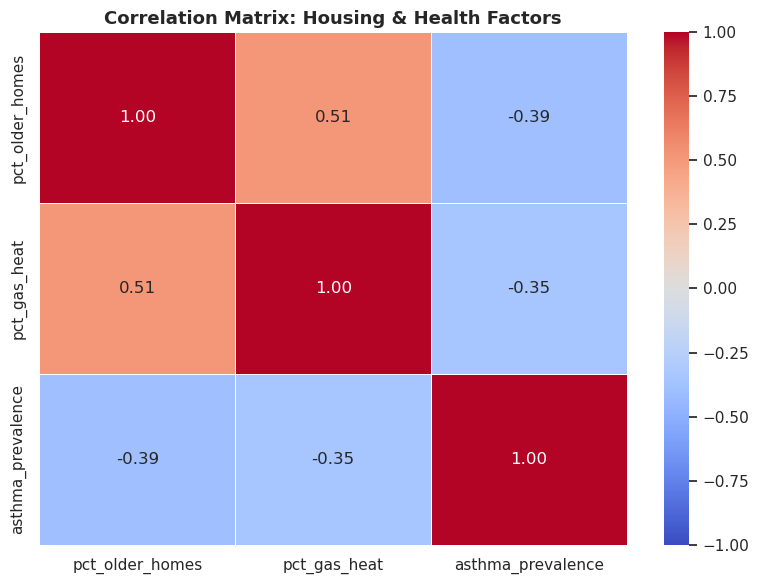

In [16]:
plt.figure(figsize=(8, 6))
correlation_matrix = df_merged[['pct_older_homes', 'pct_gas_heat', 'asthma_prevalence']].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,          # Show the correlation numbers inside the boxes
    cmap='coolwarm',     # Color scheme (blue = negative, red = positive)
    vmin=-1, vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title('Correlation Matrix: Housing & Health Factors', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

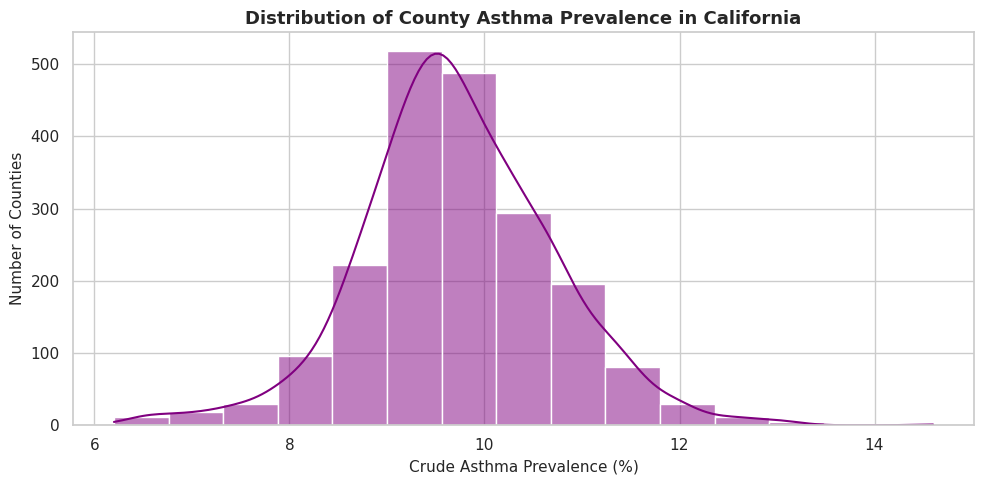

In [17]:
plt.figure(figsize=(10, 5))

# Plotting the distribution of asthma prevalence across counties
sns.histplot(
    data=df_merged,
    x='asthma_prevalence',
    kde=True,            # Adds a smooth curve over the bars
    color='purple',
    bins=15
)
plt.title('Distribution of County Asthma Prevalence in California', fontsize=13, fontweight='bold')
plt.xlabel('Crude Asthma Prevalence (%)', fontsize=11)
plt.ylabel('Number of Counties', fontsize=11)
plt.tight_layout()
plt.show()